# 4 · Two follow-up checks

**Check 1: train on synthetic, test on real.** Remove *all* real images of the 7 minority classes and teach the classifier those classes from generated images alone.
If the generated images carry the real disease features, the classifier should still recognise real test photos of those classes.

**Check 2: pretrained ResNet-18.** Repeat baseline vs the best method with an ImageNet-pretrained backbone, to see whether the conclusion depends on the small custom CNN.

Both use 3 seeds (0-2) and the main CNN where relevant. "±" is the sample standard deviation over seeds (the same one the decision rule uses).

In [1]:
%matplotlib inline
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import study
from study import metrics, LEVELS, METHODS, LABEL, COLOR
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
pd.set_option("display.width", 140)

## Check 1: classes learnt from generated images only (minority macro-F1 on real test photos)

In [2]:
S = (0, 1, 2)
rows, nums = {}, {}
for label, prefix, m in [("Real images (baseline)", "", "baseline"), ("Oversampled real images", "", "oversampling"),
                         ("GAN S1 images only", "tstr_", "s1_cond_minority"), ("GAN S2 images only", "tstr_", "s2_cond_all"),
                         ("GAN S3 images only", "tstr_", "s3_per_class")]:
    rows[label], nums[label] = {}, {}
    for lv in LEVELS:
        v = [r["minority_macro_f1"] for r in study.load_runs(m, lv, "1", S, prefix)]
        rows[label][lv] = f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
        nums[label][lv] = np.mean(v)
tstr = pd.DataFrame(rows).T
tstr.columns = ["all real images", "100 per class", "30 per class"]
tstr

,all real images,100 per class,30 per class
Real images (baseline),0.969 ± 0.018,0.953 ± 0.008,0.110 ± 0.132
Oversampled real images,0.989 ± 0.002,0.982 ± 0.006,0.965 ± 0.009
GAN S1 images only,0.000 ± 0.000,0.021 ± 0.018,0.007 ± 0.013
GAN S2 images only,0.087 ± 0.108,0.003 ± 0.004,0.010 ± 0.004
GAN S3 images only,0.692 ± 0.009,0.760 ± 0.007,0.801 ± 0.037


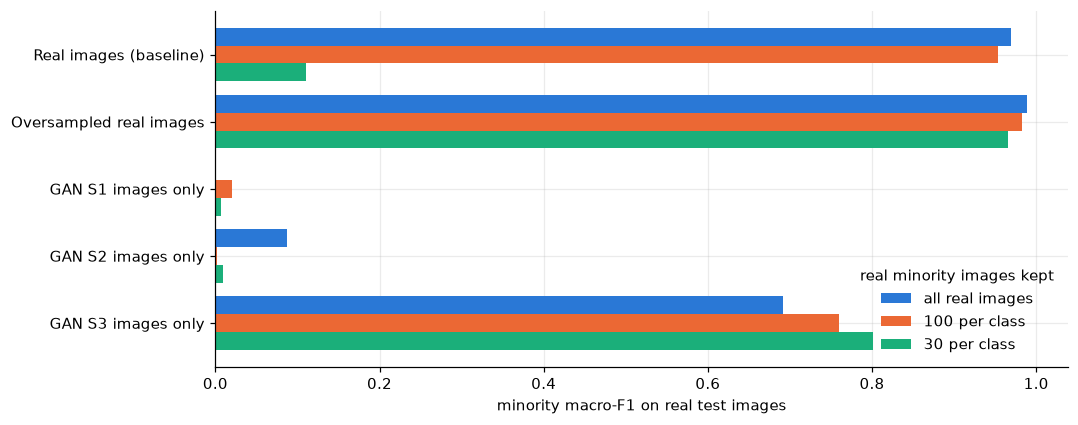

In [3]:
num = pd.DataFrame(nums).T
num.columns = ["all real images", "100 per class", "30 per class"]
ax = num.plot.barh(figsize=(10, 4.2), width=.8, color=["#2a78d6", "#eb6834", "#1baf7a"])
ax.invert_yaxis(); ax.set_xlabel("minority macro-F1 on real test images")
ax.legend(frameon=False, title="real minority images kept")
plt.show()

**Reading it:** images from S1 and S2 carry almost none of the real disease signal (scores near 0), consistent with S1's collapse. S2's images look realistic and varied (good KID and diversity) but do not carry the class-specific signal. S3 carries some
(about 0.69 to 0.80) but far less than real or oversampled photos (0.95 to 0.99; the baseline at 30 images is the exception). The S3 score *rises* as real data shrinks,
which fits a GAN that copies its few training images instead of inventing new ones: at 30 images several classes show 25% to 54% near-copies (memorisation table in notebook 2).

## Check 2: pretrained ResNet-18

In [4]:
rows = {}
for label, m in [("Baseline", "baseline"), ("Oversampling", "oversampling")]:
    rows[label] = {}
    for lv in LEVELS:
        v = [r["minority_macro_f1"] for r in study.load_runs(m, lv, "1", S, "r18_")]
        rows[label][lv] = f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}"
r18 = pd.DataFrame(rows).T
r18.columns = ["all real images", "100 per class", "30 per class"]
r18

,all real images,100 per class,30 per class
Baseline,0.994 ± 0.003,0.988 ± 0.006,0.966 ± 0.013
Oversampling,0.992 ± 0.007,0.999 ± 0.001,0.987 ± 0.005


A pretrained backbone removes most of the imbalance problem by itself: the baseline at 30 images per class scores about 0.97 here, against about 0.12 for the small custom CNN.
Oversampling still matches or beats the baseline.

## Take-away

For this dataset, generating images with a GAN did not help beyond repeating the real ones, and the choice of model (a pretrained backbone) mattered far more than any balancing trick.
Per-run numbers are in [`experiment/results/`](../experiment/results/).